In [25]:
import pandas as pd
import numpy as np
import re
import nltk
import joblib
from nltk.corpus import stopwords
from gensim.models import Word2Vec
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import  LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score)
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout)
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt
import seaborn as sns

In [26]:
df=pd.read_csv('/Users/nidagallusandeep/Downloads/IMDB Dataset 2.csv')

In [27]:
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [28]:
df.shape

(50000, 2)

In [29]:
df.columns

Index(['review', 'sentiment'], dtype='object')

In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB


In [31]:
df.isnull().sum()

review       0
sentiment    0
dtype: int64

In [32]:
df.duplicated().sum()

np.int64(418)

In [33]:
df["sentiment"].value_counts()

sentiment
positive    25000
negative    25000
Name: count, dtype: int64

In [35]:
df.dropna(inplace=True)
df.drop_duplicates(subset=['review'],inplace=True)
df.reset_index(drop=True, inplace=True)

In [36]:
def clean_text(text):
    text = text.lower()
# Remove HTML tags
    text = re.sub(r'<.*?>', '', text)
# Remove special characters
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
# Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()
    return text

In [37]:
df['clean_review'] = df['review'].apply(clean_text)
df[['review', 'clean_review']].head()

,review,clean_review
0,One of the other reviewers has mentioned that ...,one of the other reviewers has mentioned that ...
1,A wonderful little production. <br /><br />The...,a wonderful little production the filming tech...
2,I thought this was a wonderful way to spend ti...,i thought this was a wonderful way to spend ti...
3,Basically there's a family where a little boy ...,basically there s a family where a little boy ...
4,"Petter Mattei's ""Love in the Time of Money"" is...",petter mattei s love in the time of money is a...


In [38]:
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))
# Preserve negation words
stop_words = stop_words - {'not', 'no', 'nor'}

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/nidagallusandeep/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [39]:
def preprocess_text(text):
    tokens = text.split()
    tokens = [
        word for word in tokens
        if word not in stop_words]
    return tokens

In [40]:
df['tokens'] = df['clean_review'].apply(preprocess_text)
df[['clean_review', 'tokens']].head()

,clean_review,tokens
0,one of the other reviewers has mentioned that ...,"[one, reviewers, mentioned, watching, oz, epis..."
1,a wonderful little production the filming tech...,"[wonderful, little, production, filming, techn..."
2,i thought this was a wonderful way to spend ti...,"[thought, wonderful, way, spend, time, hot, su..."
3,basically there s a family where a little boy ...,"[basically, family, little, boy, jake, thinks,..."
4,petter mattei s love in the time of money is a...,"[petter, mattei, love, time, money, visually, ..."


In [42]:
X = df['tokens']
y = df['sentiment']

In [43]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print("Training Data:", len(X_train))
print("Testing Data:", len(X_test))

Training Data: 39665
Testing Data: 9917


# Word2Vec Model

In [44]:
w2v_model = Word2Vec(
    sentences=X_train.tolist(),
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    sg=1,
    epochs=10,
    seed=42)

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_fl

# Check vocabulary:

# Check vocabulary:

In [48]:
print("Vocabulary Size:", len(w2v_model.wv))

Vocabulary Size: 56649


# Check word vector:

In [49]:
print(w2v_model.wv['movie'])

[ 0.08803292 -0.08418688  0.01011086 -0.0346349   0.1185683   0.05487381
  0.10921519  0.13560228  0.01367599 -0.21420504 -0.298731    0.00363743
  0.12247142  0.23918936  0.01567417  0.11584754  0.09220243 -0.35423097
 -0.32721242  0.20191495  0.05578603 -0.21174821 -0.15485485  0.18083648
  0.17007692  0.5471923  -0.05755772  0.11713003 -0.29337493 -0.13759835
 -0.03883725 -0.21007709  0.06697284  0.05856971  0.1839184  -0.16678813
  0.2006262  -0.5807308   0.03044715  0.27089033 -0.09127036  0.10751717
  0.3385883   0.06165545 -0.13149197  0.17434573  0.01776343  0.1634769
  0.50458956 -0.01719501  0.20097476 -0.6507594  -0.06118351 -0.05659882
  0.21577436 -0.23552644 -0.03192187  0.18775615 -0.16865328  0.14622885
  0.13652751 -0.04435284 -0.37298256  0.43430078 -0.19669172 -0.04485116
  0.30326286 -0.28723136  0.18176615 -0.13883299  0.1643354  -0.00700793
 -0.16903839 -0.06247034  0.1846631  -0.18209688  0.02777484 -0.23345074
 -0.11419615  0.19722359  0.19795853 -0.41145945 -0.

# Similar words:

In [50]:
w2v_model.wv.most_similar('movie')

[('film', 0.8909597396850586),
 ('atleast', 0.8067837953567505),
 ('fffc', 0.788515031337738),
 ('immortel', 0.7852305769920349),
 ('havn', 0.7778085470199585),
 ('definetely', 0.7764517664909363),
 ('havent', 0.7742772102355957),
 ('flick', 0.7721633911132812),
 ('missfortune', 0.7720499634742737),
 ('movies', 0.7673253417015076)]

# Feature Extraction
- Convert each review into a 100-dimensional vector using average Word2Vec embedding

In [52]:
def get_sentence_vector(tokens, model):
    vectors = [
        model.wv[word]
        for word in tokens
        if word in model.wv]
    if len(vectors) == 0:
        return np.zeros(model.vector_size)
    return np.mean(vectors, axis=0)

In [53]:
X_train_vec = np.array([get_sentence_vector(tokens, w2v_model)for tokens in X_train])
X_test_vec = np.array([get_sentence_vector(tokens, w2v_model)for tokens in X_test])

In [54]:
print(X_train_vec.shape)
print(X_test_vec.shape)

(39665, 100)
(9917, 100)


# Label Encoding

In [55]:
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)
print(le.classes_)

['negative' 'positive']


In [56]:
model = Sequential([
    Input(shape=(100,)),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')])

In [57]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy'])

In [58]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        12,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,249 (83.00 KB)

 Trainable params: 21,249 (83.00 KB)

 Non-trainable params: 0 (0.00 B)

# Model Training
- Use EarlyStopping to reduce unnecessary training.

In [59]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True)

In [60]:
history = model.fit(
    X_train_vec,
    y_train_enc,
    epochs=15,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stop])

Epoch 1/15
496/496 ━━━━━━━━━━━━━━━━━━━━ 1s 866us/step - accuracy: 0.8206 - loss: 0.3992 - val_accuracy: 0.8676 - val_loss: 0.3110
Epoch 2/15
496/496 ━━━━━━━━━━━━━━━━━━━━ 0s 676us/step - accuracy: 0.8675 - loss: 0.3145 - val_accuracy: 0.8780 - val_loss: 0.2947
Epoch 3/15
496/496 ━━━━━━━━━━━━━━━━━━━━ 0s 668us/step - accuracy: 0.8721 - loss: 0.3053 - val_accuracy: 0.8723 - val_loss: 0.3001
Epoch 4/15
496/496 ━━━━━━━━━━━━━━━━━━━━ 0s 678us/step - accuracy: 0.8738 - loss: 0.3015 - val_accuracy: 0.8709 - val_loss: 0.3071
Epoch 5/15
496/496 ━━━━━━━━━━━━━━━━━━━━ 0s 669us/step - accuracy: 0.8750 - loss: 0.2967 - val_accuracy: 0.8782 - val_loss: 0.2888
Epoch 6/15
496/496 ━━━━━━━━━━━━━━━━━━━━ 0s 680us/step - accuracy: 0.8782 - loss: 0.2947 - val_accuracy: 0.8794 - val_loss: 0.2890
Epoch 7/15
496/496 ━━━━━━━━━━━━━━━━━━━━ 0s 666us/step - accuracy: 0.8783 - loss: 0.2921 - val_accuracy: 0.8802 - val_loss: 0.2898
Epoch 8/15
496/496 ━━━━━━━━━━━━━━━━━━━━ 0s 677us/step - accuracy: 0.8782 - loss: 0.2913 - 

# Model Evaluation

In [61]:
loss, accuracy = model.evaluate(X_test_vec,y_test_enc)
print("Test Loss:", loss)
print("Test Accuracy:", accuracy * 100)

310/310 ━━━━━━━━━━━━━━━━━━━━ 0s 436us/step - accuracy: 0.8788 - loss: 0.2901
Test Loss: 0.2900736927986145
Test Accuracy: 87.8794014453888


# Predictions

In [62]:
y_pred_prob = model.predict(X_test_vec)
y_pred = (y_pred_prob >= 0.5).astype(int).ravel()

310/310 ━━━━━━━━━━━━━━━━━━━━ 0s 347us/step


# Classification report:

In [63]:
print(classification_report(y_test_enc,y_pred,target_names=le.classes_))

              precision    recall  f1-score   support

    negative       0.88      0.88      0.88      4940
    positive       0.88      0.88      0.88      4977

    accuracy                           0.88      9917
   macro avg       0.88      0.88      0.88      9917
weighted avg       0.88      0.88      0.88      9917



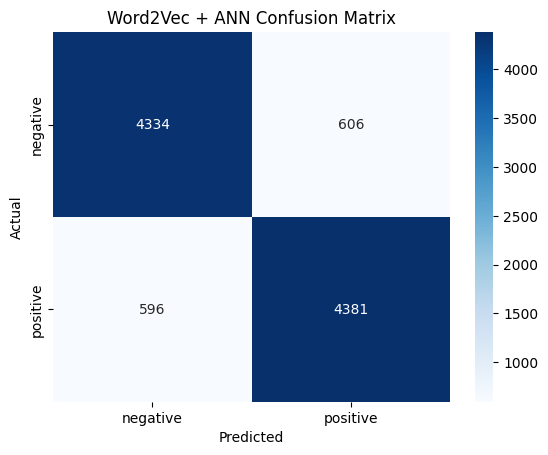

In [64]:
cm = confusion_matrix(y_test_enc, y_pred)
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=le.classes_,
    yticklabels=le.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Word2Vec + ANN Confusion Matrix")
plt.show()

# ROC-AUC:

In [65]:
auc = roc_auc_score(y_test_enc, y_pred_prob)
print("ROC-AUC Score:", auc)

ROC-AUC Score: 0.9491963029937713


# Accuracy graph:

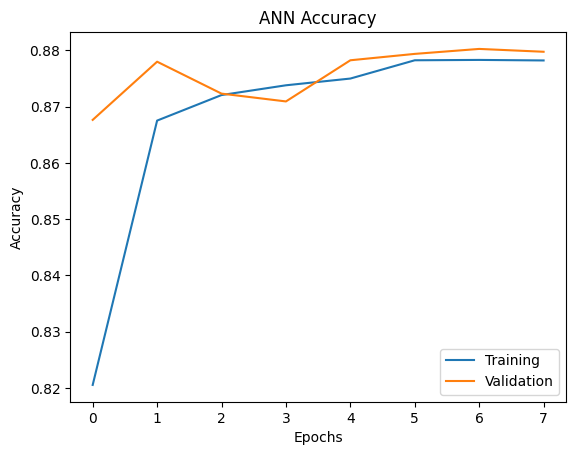

In [66]:
plt.plot(history.history['accuracy'], label='Training')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("ANN Accuracy")
plt.legend()
plt.show()

# Save Models

In [67]:
model.save("word2vec_ann.keras")
w2v_model.save("word2vec.model")
joblib.dump(le, "label_encoder.pkl")
print("All models saved successfully!")

All models saved successfully!


# Real-Time Prediction

In [69]:
def predict_sentiment(text):
    cleaned = clean_text(text)
    tokens = preprocess_text(cleaned)
    vector = get_sentence_vector(
        tokens,
        w2v_model)
    vector = vector.reshape(1, -1)
    probability = model.predict(
        vector,
        verbose=0
    )[0][0]
    if probability >= 0.5:
        sentiment = "Positive"
    else:
        sentiment = "Negative"
    return {
        "Sentiment": sentiment,
        "Confidence": round(
            max(probability, 1-probability) * 100, 2)}

In [70]:
predict_sentiment("This movie is amazing and wonderful")

{'Sentiment': 'Positive', 'Confidence': np.float32(100.0)}

In [71]:
predict_sentiment("This movie is boring and worst")

{'Sentiment': 'Negative', 'Confidence': np.float32(100.0)}